# 🏏 CS-471: Machine Learning - Complex Engineering Problem (CEP)
## First Innings Total Runs Predictor (ODI & T20)

**Author:** [Your Name/Group ID]  
**Date:** [Current Date]  
**Course:** CS-471 Machine Learning  

---

### 1. Problem Statement
The objective of this project is to predict the **total runs scored by a team in the first innings** of an ODI or T20 cricket match. This is a **regression problem**. 

We will allow the user to predict the final score based on the **current match state** (e.g., at the end of the 10th over, with 2 wickets down).

### 2. Dataset
- **Source:** Cricsheet Ball-by-Ball Data
- **Target Variable:** `total_runs` (Final score of the innings)
- **Formats:** ODI (One Day International) and T20 (Twenty20)

### 3. Methodology
1. **Data Cleaning & Filtering**: Extract ODI/T20 matches, Filter 1st innings.
2. **Feature Engineering**: Create state-based features (Current Score, Wickets Lost, Balls Remaining, Run Rate).
3. **EDA**: Visualize scoring trends, wicket impact, and venue statistics.
4. **Modeling**: Train Linear Regression, Random Forest, and XGBoost models.
5. **Evaluation**: Compare models using MAE, RMSE, and R2 Score.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import warnings

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

print("✅ Libraries Imported Successfully")


✅ Libraries Imported Successfully


In [3]:
# Load the dataset
file_path = r"D:\5th Semester\Machine Learning\CEA\ML CEA\cricsheet_merged_data.csv"
try:
    df = pd.read_csv(file_path)
    print(f"✅ Dataset Loaded. Shape: {df.shape}")
    display(df.head())
except FileNotFoundError:
    print(f"❌ File not found at {file_path}. Please check the path.")


✅ Dataset Loaded. Shape: (10645589, 20)


,match_id,date,city,match_type,gender,team_a,team_b,winner,inning,batting_team,ball,batsman,non_striker,bowler,batsman_runs,extras,total_runs,is_wicket,player_out,dismissal_kind
0,1000851,2016-11-03,Perth,Test,male,Australia,South Africa,South Africa,1st innings,South Africa,0.1,SC Cook,D Elgar,MA Starc,0,0,0,0,NaN,NaN
1,1000851,2016-11-03,Perth,Test,male,Australia,South Africa,South Africa,1st innings,South Africa,0.2,SC Cook,D Elgar,MA Starc,0,0,0,0,NaN,NaN
2,1000851,2016-11-03,Perth,Test,male,Australia,South Africa,South Africa,1st innings,South Africa,0.3,SC Cook,D Elgar,MA Starc,0,0,0,0,NaN,NaN
3,1000851,2016-11-03,Perth,Test,male,Australia,South Africa,South Africa,1st innings,South Africa,0.4,SC Cook,D Elgar,MA Starc,0,0,0,1,SC Cook,caught
4,1000851,2016-11-03,Perth,Test,male,Australia,South Africa,South Africa,1st innings,South Africa,0.5,HM Amla,D Elgar,MA Starc,0,0,0,0,NaN,NaN


## 1. Data Cleaning & Filtering
We strictly need:
- **Formats:** ODI and T20
- **Inning:** 1st Innings only (Predicting target for 2nd innings team)


In [4]:
# 1. Filter match types
allowed_types = ['ODI'] # Standardizing names if needed based on data inspection
df_filtered = df[df['match_type'].isin(allowed_types)].copy()

# 2. Filter 1st Innings
# 'inning' column usually contains '1st innings', '2nd innings'. Check unique values first.
# print(df_filtered['inning'].unique())
df_filtered = df_filtered[df_filtered['inning'] == '1st innings']

# 3. Handle Missing Values
# Drop rows where critical info like batsman/bowler is missing, but usually ball-by-ball is clean.
df_filtered.dropna(subset=['batsman', 'bowler', 'total_runs'], inplace=True)

print(f"✅ Data Filtered. New Shape: {df_filtered.shape}")
print(f"Matches in dataset: {df_filtered['match_id'].nunique()}")


✅ Data Filtered. New Shape: (885197, 20)
Matches in dataset: 3073


## 2. Feature Engineering
We need to convert ball-by-ball data into **match-state** data.
For every ball, we want to know:
- **Current Score**: Sum of runs so far.
- **Wickets Left**: 10 - Wickets fallen so far.
- **Balls Left**: Total balls (300 for ODI, 120 for T20) - balls bowled.
- **Run Rate**: Current Run Rate (CRR).
- **Target (Y)**: The FINAL total score of that innings.

This step aggregates data match-wise to calculate the final score, then merges it back.


In [5]:
# --- Derive Bowling Team ---
def get_bowling_team(row):
    if row['batting_team'] == row['team_a']:
        return row['team_b']
    return row['team_a']

df_filtered['bowling_team'] = df_filtered.apply(get_bowling_team, axis=1)
print("✅ Bowling Team derived successfully.")

# Calculate Final Score per Match
match_totals = df_filtered.groupby('match_id')['total_runs'].sum().reset_index()
match_totals.rename(columns={'total_runs': 'final_total_runs'}, inplace=True)

# Merge back
df_merged = df_filtered.merge(match_totals, on='match_id')

# --- Feature extraction per ball ---
# Group by match to calculate cumulative sums
df_merged['ball_runs'] = df_merged['batsman_runs'] + df_merged['extras']
df_merged['cum_runs'] = df_merged.groupby('match_id')['ball_runs'].cumsum()
df_merged['cum_wickets'] = df_merged.groupby('match_id')['is_wicket'].cumsum()

# Feature: Balls Bowled
# 'ball' column is usually 0.1, 0.2 ...
# We can just count the row number per match to get accurate balls bowled including wides/no-balls if needed, 
# But strictly 'overs' * 6 + ball number is better.
# For simplicity in this dataset, let's assume standard legal delivery counting or row count approximation.
# Let's derive 'legal_balls_bowled' roughly or use row index per match.
df_merged['balls_bowled'] = df_merged.groupby('match_id').cumcount() + 1

# Feature: Total Overs & Balls allowed
def get_total_balls(match_type):
    if match_type == 'ODI': return 300
    if match_type == 'T20' or match_type == 'T20I': return 120
    return 0

df_merged['max_balls'] = df_merged['match_type'].apply(get_total_balls)
df_merged['balls_left'] = df_merged['max_balls'] - df_merged['balls_bowled']
df_merged['wickets_left'] = 10 - df_merged['cum_wickets']
df_merged['crr'] = (df_merged['cum_runs'] * 6) / df_merged['balls_bowled']

# Filter out rows where balls_left < 0 (super overs or data errors)
df_merged = df_merged[df_merged['balls_left'] >= 0]

# Selection of model-ready dataframe
# We pick snapshots of the game. For Training, we can use every ball, 
# OR to reduce size/noise, take samples (e.g., end of every over).
# Let's using every ball for maximum data, but remove first 5 overs where CRR is noisy.
df_model = df_merged[df_merged['balls_bowled'] > 30].copy()

final_features = ['match_id', 'match_type', 'venue', 'batting_team', 'bowling_team', 
                  'cum_runs', 'wickets_left', 'balls_left', 'crr', 'final_total_runs']

# Note: 'venue' might be 'city' in your dataset. Adjust run-time.
if 'city' in df_model.columns:
    df_model.rename(columns={'city': "venue"}, inplace=True)

try:
    dataset = df_model[final_features]
except KeyError as e:
    print(f"Column missing: {e}. Available: {df_model.columns}")
    # Fallback if venue not found
    final_features = [f for f in final_features if f != 'venue']
    dataset = df_model[final_features]

print(f"✅ Feature Engineering Complete. Dataset Shape: {dataset.shape}")
display(dataset.head())


✅ Bowling Team derived successfully.
✅ Feature Engineering Complete. Dataset Shape: (775954, 10)


,match_id,match_type,venue,batting_team,bowling_team,cum_runs,wickets_left,balls_left,crr,final_total_runs
30,1000887,ODI,Brisbane,Australia,Pakistan,13,8,269,2.516129,268
31,1000887,ODI,Brisbane,Australia,Pakistan,14,8,268,2.625000,268
32,1000887,ODI,Brisbane,Australia,Pakistan,15,8,267,2.727273,268
33,1000887,ODI,Brisbane,Australia,Pakistan,16,8,266,2.823529,268
34,1000887,ODI,Brisbane,Australia,Pakistan,20,8,265,3.428571,268


## 3. Exploratory Data Analysis (EDA)
Visualizing relationships between features and the target.


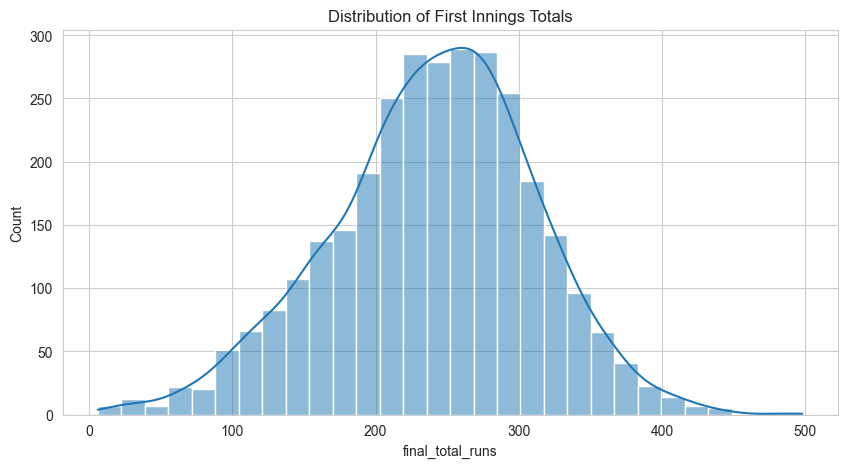

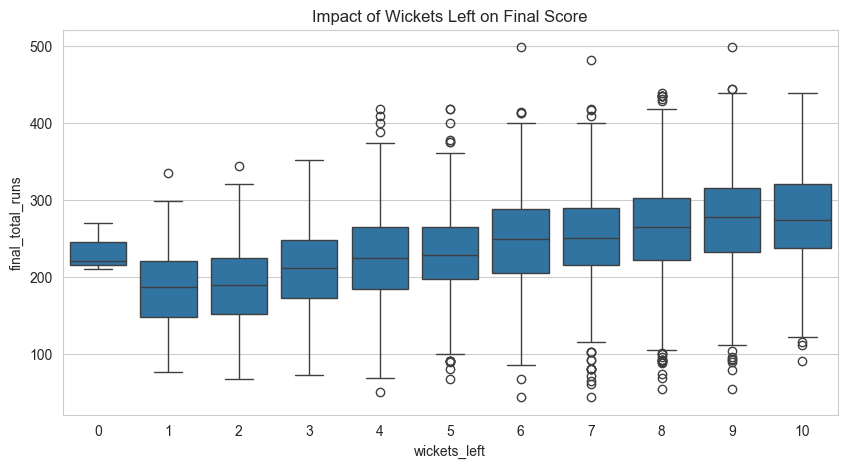

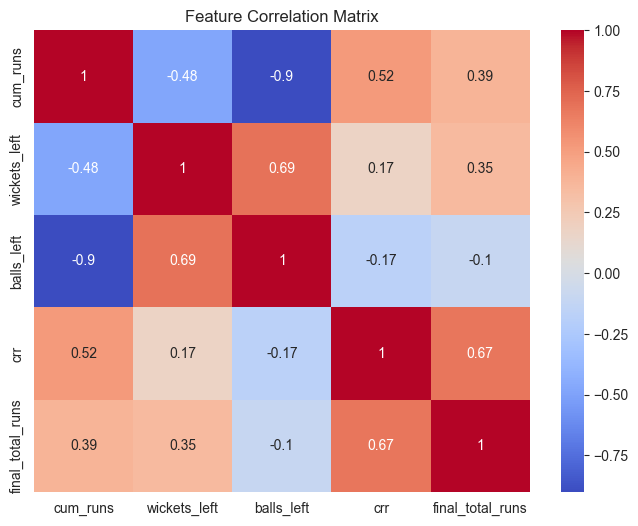

In [6]:
# 1. Distribution of Total Runs (Target)
plt.figure(figsize=(10,5))
sns.histplot(data=match_totals, x='final_total_runs', kde=True, bins=30)
plt.title('Distribution of First Innings Totals')
plt.show()

# 2. Runs vs Wickets Left (General Trend)
plt.figure(figsize=(10,5))
sns.boxplot(x='wickets_left', y='final_total_runs', data=dataset.sample(5000))
plt.title('Impact of Wickets Left on Final Score')
plt.show()

# 3. Correlation Heatmap
corr_matrix = dataset.select_dtypes(include=np.number).corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Feature Correlation Matrix')
plt.show()


In [7]:
# One-Hot Encoding for Teams and Venue
# This increases dimensionality. For high-cardinality like Venue, maybe Top 10 + Other?
# For simplicity, we use Label Encoding or One-Hot. Let's use One-Hot for Teams (limited set) and Dummy for match_type.

dataset_encoded = pd.get_dummies(dataset, columns=['batting_team', 'bowling_team', 'match_type'], drop_first=True)

# Drop textual columns or high cardinality columns like 'venue' for strict regression baseline 
# (unless we frequency encode it). Let's Drop venue for now to avoid massive sparsity or memory issues on student PC.
if 'venue' in dataset_encoded.columns:
    dataset_encoded.drop('venue', axis=1, inplace=True)
    
X = dataset_encoded.drop(['match_id', 'final_total_runs'], axis=1)
y = dataset_encoded['final_total_runs']

# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training Features: {X_train.shape}")
print(f"Testing Features: {X_test.shape}")


Training Features: (620763, 57)
Testing Features: (155191, 57)


## 4. Model Training
We will train three models:
1. **Linear Regression**: Baseline.
2. **Random Forest regressor**: Capture non-linearity.
3. **XGBoost Regressor**: High performance gradient boosting.


In [8]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=50, max_depth=10, n_jobs=-1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=6, n_jobs=-1, random_state=42)
}

results = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    
    results[name] = {"MAE": mae, "RMSE": rmse, "R2": r2}
    print(f"  -> R2 Score: {r2:.3f}")

# Display Results
results_df = pd.DataFrame(results).T
display(results_df)


Training Linear Regression...
  -> R2 Score: 0.617
Training Random Forest...
  -> R2 Score: 0.665
Training XGBoost...
  -> R2 Score: 0.686


,MAE,RMSE,R2
Linear Regression,30.260598,40.572228,0.617435
Random Forest,27.701016,37.982182,0.664720
XGBoost,26.749975,36.752066,0.686086


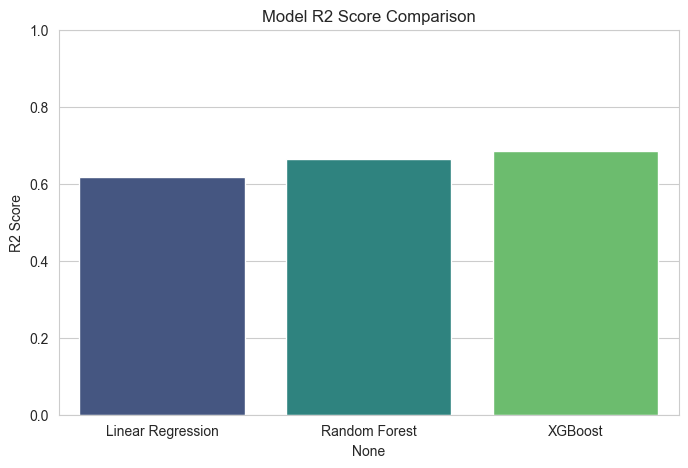

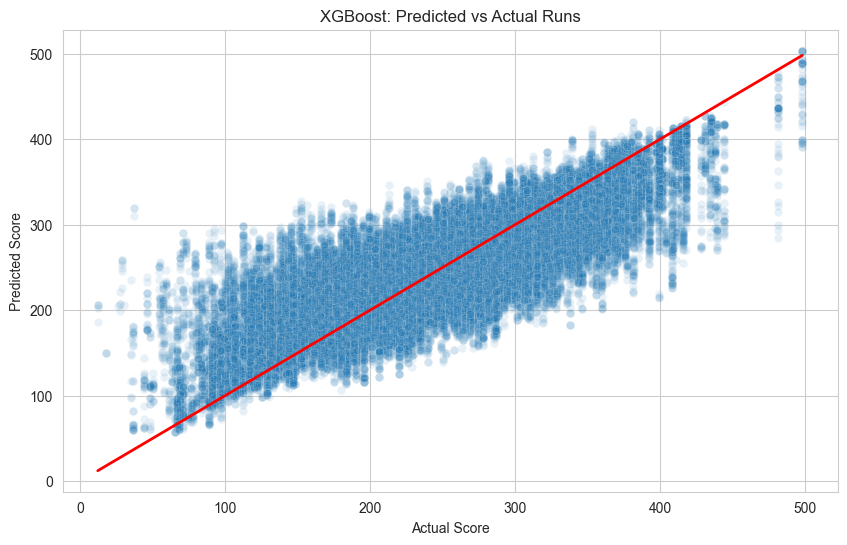

In [9]:
# Plot R2 Scores
plt.figure(figsize=(8,5))
sns.barplot(x=results_df.index, y=results_df['R2'], palette='viridis')
plt.title('Model R2 Score Comparison')
plt.ylim(0, 1)
plt.ylabel('R2 Score')
plt.show()

# Pred vs Actual for Best Model (likely XGBoost)
best_model_name = results_df['R2'].idxmax()
best_model = models[best_model_name]
y_pred_best = best_model.predict(X_test)

plt.figure(figsize=(10,6))
sns.scatterplot(x=y_test, y=y_pred_best, alpha=0.1)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', lw=2)
plt.xlabel("Actual Score")
plt.ylabel("Predicted Score")
plt.title(f"{best_model_name}: Predicted vs Actual Runs")
plt.show()


## 5. Live Prediction
Function to predict score based on user input.


In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

def predict_score(batting_team, bowling_team, overs, runs, wickets, match_type='ODI'):
    # 1. Create a DataFrame for the single input
    input_data = {
        'cum_runs': [runs],
        'wickets_left': [10 - wickets],
        'balls_left': [ (300 if match_type=='ODI' else 120) - (overs * 6) ],
        'crr': [ runs / overs if overs > 0 else 0 ],
        'batting_team': [batting_team],
        'bowling_team': [bowling_team],
        'match_type': [match_type]
    }
    
    df_input = pd.DataFrame(input_data)
    
    # 2. Encode categorical variables
    # We use pd.get_dummies on this single row. 
    # This might result in fewer columns than X_train if the specific teams aren't in columns yet, 
    # or different columns. We must align it.
    df_input_encoded = pd.get_dummies(df_input, columns=['batting_team', 'bowling_team', 'match_type'])
    
    # 3. Align columns with Training Data (X_train)
    # This ensures the input vector has exactly the same columns as the model expects.
    # Missing columns (e.g., other teams) will be filled with 0.
    df_final = df_input_encoded.reindex(columns=X_train.columns, fill_value=0)
    
    # 4. Predict
    prediction = best_model.predict(df_final)[0]
    return prediction

# --- Interactive Widgets ---
style = {'description_width': 'initial'}

batting_team_widget = widgets.Dropdown(options=dataset['batting_team'].unique(), description='Batting Team:', style=style)
bowling_team_widget = widgets.Dropdown(options=dataset['bowling_team'].unique(), description='Bowling Team:', style=style)
overs_widget = widgets.FloatSlider(value=10, min=0, max=50, step=0.1, description='Overs Completed:', style=style)
runs_widget = widgets.IntText(value=60, description='Current Score:', style=style)
wickets_widget = widgets.IntSlider(value=2, min=0, max=9, description='Wickets Fallen:', style=style)
match_type_widget = widgets.Dropdown(options=['ODI', 'T20'], description='Match Types:', style=style)
predict_btn = widgets.Button(description="Predict Final Score", button_style='success')
output_widget = widgets.Output()

def on_predict_clicked(b):
    with output_widget:
        clear_output()
        pred = predict_score(
            batting_team_widget.value,
            bowling_team_widget.value,
            overs_widget.value,
            runs_widget.value,
            wickets_widget.value,
            match_type_widget.value
        )
        print(f"\n🏏 Match: {batting_team_widget.value} vs {bowling_team_widget.value} ({match_type_widget.value})")
        print(f"📊 Current State: {overs_widget.value:.1f} overs, {runs_widget.value}/{wickets_widget.value}")
        print(f"🔮 Predicted Final Score: {int(pred)}")

predict_btn.on_click(on_predict_clicked)

display(widgets.VBox([
    batting_team_widget, bowling_team_widget, 
    match_type_widget, overs_widget, 
    runs_widget, wickets_widget, 
    predict_btn, output_widget
]))
